# Terra Shift — Data Collection
## 1. Environment and API Setup

In [2]:
from pathlib import Path
from dotenv import load_dotenv
import os

# Find the project folder and load its .env file
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_DIR / ".env")

CENSUS_API_KEY = os.getenv("CENSUS_API_KEY")

if CENSUS_API_KEY:
    print("Census API key loaded successfully.")
else:
    print("API key not found. Check that .env is in the terra-shift project folder.")

Census API key loaded successfully.


## 2. Fetching 2024 ACS Data

We are collecting:
- Total population
- Civilian employed population (age 16+)
- Total housing units

Source: US Census Bureau — ACS 5-Year Estimates, 2024.

In [3]:
import requests
import pandas as pd

# Census API endpoint for 2024 ACS 5-Year Estimates
BASE_URL = "https://api.census.gov/data/2024/acs/acs5"

# Variables we want to collect
variables = [
    "NAME",
    "B01003_001E",  # Total population
    "B01003_001M",  # Population margin of error
    "B23025_004E",  # Civilian employed population (16+)
    "B23025_004M",  # Employment margin of error
    "B25001_001E",  # Total housing units
    "B25001_001M"   # Housing units margin of error
]

params = {
    "get": ",".join(variables),
    "for": "metropolitan statistical area/micropolitan statistical area:*",
    "key": CENSUS_API_KEY
}

# Send request
response = requests.get(BASE_URL, params=params, timeout=60)

print("HTTP Status:", response.status_code)

# Check whether the request succeeded
response.raise_for_status()

# Convert the API response into a DataFrame
data = response.json()

df_2024 = pd.DataFrame(data[1:], columns=data[0])

print("Total records received:", len(df_2024))
print("\nColumns received:")
print(df_2024.columns.tolist())

print("\nFirst 5 records:")
display(df_2024.head())

HTTP Status: 200
Total records received: 935

Columns received:
['NAME', 'B01003_001E', 'B01003_001M', 'B23025_004E', 'B23025_004M', 'B25001_001E', 'B25001_001M', 'metropolitan statistical area/micropolitan statistical area']

First 5 records:


,NAME,B01003_001E,B01003_001M,B23025_004E,B23025_004M,B25001_001E,B25001_001M,metropolitan statistical area/micropolitan statistical area
0,"Aberdeen, SD Micro Area",41925,-555555555,21733,621,19988,77,10100
1,"Aberdeen, WA Micro Area",77053,-555555555,29849,880,36967,70,10140
2,"Abilene, TX Metro Area",180408,-555555555,80232,1653,75799,288,10180
3,"Ada, OK Micro Area",38235,-555555555,17599,391,17531,64,10220
4,"Adrian, MI Micro Area",98415,-555555555,44757,822,43761,177,10300


## 3. Cleaning the 2024 Metro Dataset

We will:

1. Preserve the original API response for reference.
2. Keep only Metropolitan Statistical Areas and exclude Micropolitan Statistical Areas because our model focuses on larger urban regions.
3. Convert measurement columns into appropriate numeric data types while preserving the metro ID as a string.
4. Handle Census special values correctly:
   - For population MOE (`B01003_001M`), replace `-555555555` with `0`, as it represents a controlled estimate.
   - Replace other unavailable or inapplicable special values with `NaN`.
5. Rename columns to make them easier to understand and use.
6. Add the ACS survey period for future comparison.

In [4]:
# Keep an untouched copy of the original API response
df_2024_raw = df_2024.copy()

# Identify the geographic ID column
geo_column = "metropolitan statistical area/micropolitan statistical area"

# Keep only metropolitan areas
# Micropolitan areas are excluded because our model focuses on larger urban regions
df_2024_metro = df_2024[
    df_2024["NAME"].str.endswith("Metro Area", na=False)
].copy()

# Rename columns to simpler names
df_2024_metro = df_2024_metro.rename(columns={
    "NAME": "metro_name",
    geo_column: "metro_id",
    "B01003_001E": "population",
    "B01003_001M": "population_moe",
    "B23025_004E": "employed_population",
    "B23025_004M": "employment_moe",
    "B25001_001E": "housing_units",
    "B25001_001M": "housing_moe"
})

# Preserve metro ID as a string
df_2024_metro["metro_id"] = df_2024_metro["metro_id"].astype("string")

# Remove the "Metro Area" suffix from names
df_2024_metro["metro_name"] = (
    df_2024_metro["metro_name"]
    .str.replace(r"\s+Metro Area$", "", regex=True)
    .str.strip()
)

# Convert measurement columns into numeric types
numeric_columns = [
    "population",
    "population_moe",
    "employed_population",
    "employment_moe",
    "housing_units",
    "housing_moe"
]

for column in numeric_columns:
    df_2024_metro[column] = pd.to_numeric(
        df_2024_metro[column],
        errors="coerce"
    )

# Handle population MOE controlled estimates
df_2024_metro["population_moe"] = (
    df_2024_metro["population_moe"]
    .replace(-555555555, 0)
)

# Replace other Census special missing-value codes with NaN
special_codes = [
    -222222222,
    -333333333,
    -444444444,
    -555555555,
    -666666666,
    -777777777,
    -888888888,
    -999999999
]

other_moe_columns = [
    "employment_moe",
    "housing_moe"
]

for column in other_moe_columns:
    df_2024_metro[column] = (
        df_2024_metro[column]
        .replace(special_codes, float("nan"))
    )

# Convert estimate and MOE columns to nullable integer types
for column in numeric_columns:
    df_2024_metro[column] = df_2024_metro[column].astype("Int64")

# Add ACS period information
df_2024_metro["acs_period_start"] = 2020
df_2024_metro["acs_period_end"] = 2024

# Reset index after filtering
df_2024_metro = df_2024_metro.reset_index(drop=True)

# Display cleaned dataset information
print("Metropolitan areas:", len(df_2024_metro))

print("\nCleaned columns:")
print(df_2024_metro.columns.tolist())

print("\nData types:")
display(df_2024_metro.dtypes)

print("\nFirst five records:")
display(df_2024_metro.head())

Metropolitan areas: 393

Cleaned columns:
['metro_name', 'population', 'population_moe', 'employed_population', 'employment_moe', 'housing_units', 'housing_moe', 'metro_id', 'acs_period_start', 'acs_period_end']

Data types:


metro_name                str
population              Int64
population_moe          Int64
employed_population     Int64
employment_moe          Int64
housing_units           Int64
housing_moe             Int64
metro_id               string
acs_period_start        int64
acs_period_end          int64
dtype: object


First five records:


,metro_name,population,population_moe,employed_population,employment_moe,housing_units,housing_moe,metro_id,acs_period_start,acs_period_end
0,"Abilene, TX",180408,0,80232,1653,75799,288,10180,2020,2024
1,"Aguadilla, PR",251769,0,80070,1888,127158,1544,10380,2020,2024
2,"Akron, OH",699820,0,351492,2686,319249,197,10420,2020,2024
3,"Albany, GA",146018,0,60496,1322,67243,87,10500,2020,2024
4,"Albany, OR",130706,0,59115,1262,53315,50,10540,2020,2024


In [5]:
print("Dataset shape:", df_2024_metro.shape)

print("\nMissing values:")
display(df_2024_metro.isna().sum())

print("\nData types:")
display(df_2024_metro.dtypes)

print("\nBasic statistics:")
display(
    df_2024_metro[
        ["population", "employed_population", "housing_units"]
    ].describe().round(2)
)

Dataset shape: (393, 10)

Missing values:


metro_name             0
population             0
population_moe         0
employed_population    0
employment_moe         0
housing_units          0
housing_moe            0
metro_id               0
acs_period_start       0
acs_period_end         0
dtype: int64


Data types:


metro_name                str
population              Int64
population_moe          Int64
employed_population     Int64
employment_moe          Int64
housing_units           Int64
housing_moe             Int64
metro_id               string
acs_period_start        int64
acs_period_end          int64
dtype: object


Basic statistics:


,population,employed_population,housing_units
count,393.0,393.0,393.0
mean,742940.74,362198.33,312628.58
std,1649233.54,823440.33,663290.36
min,58082.0,20206.0,20445.0
25%,146386.0,67610.0,65459.0
50%,246989.0,115145.0,115539.0
75%,577726.0,281608.0,253987.0
max,19798537.0,9727497.0,8038666.0


## 4. Exploratory Data Analysis (EDA)

We examine the distribution, relationships and consistency of the
population, employment and housing variables across metropolitan areas.

The purpose is to identify unusual patterns and potential data-quality
issues before combining multiple ACS periods.

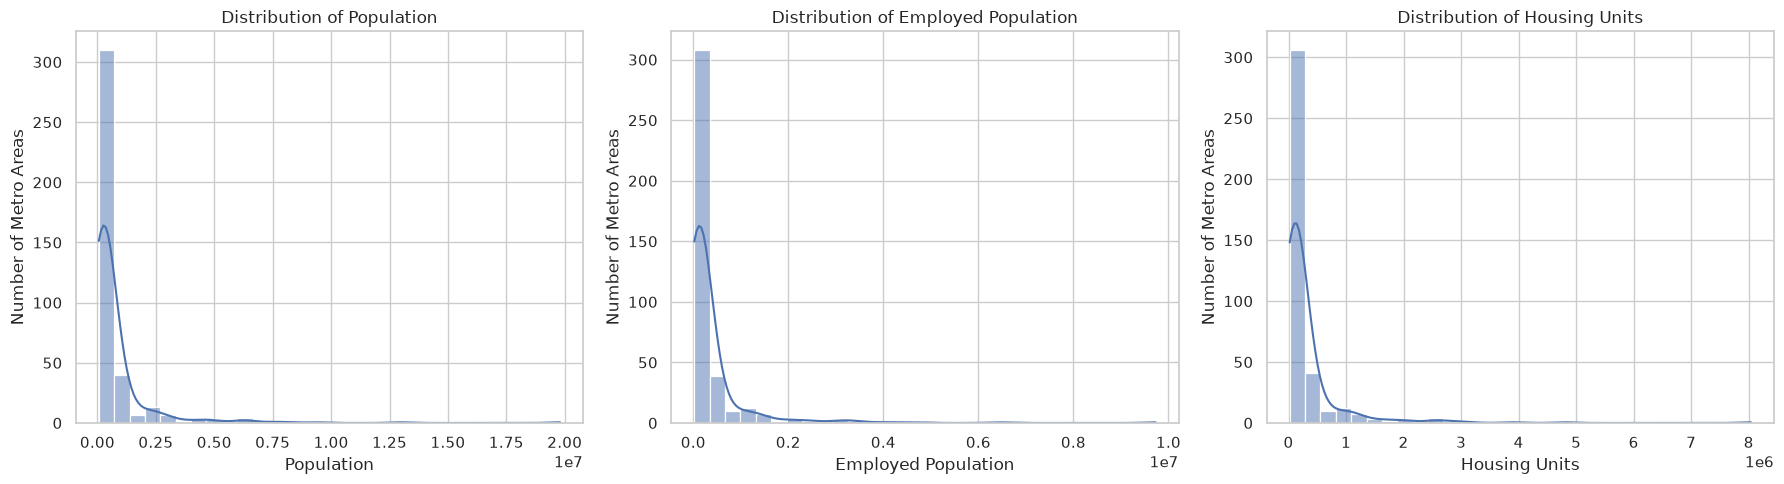

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

main_variables = [
    "population",
    "employed_population",
    "housing_units"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, main_variables):
    sns.histplot(
        data=df_2024_metro,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Metro Areas")

plt.tight_layout()
plt.show()

### Observations from Variable Distribution

The distribution plots show that population, employed population and housing units are highly right-skewed across the 393 metropolitan areas.

Most metropolitan areas have relatively smaller population, employment and housing values, whereas a small number of metropolitan areas have significantly higher values.

All three variables exhibit similar distribution patterns, indicating that the dataset contains many smaller metropolitan areas and comparatively fewer large urban regions.

The long right tails also indicate the presence of extreme observations. However, these observations are not necessarily errors, as larger metropolitan areas naturally have higher population, employment and housing counts.

**Conclusion:** The variables are not normally distributed and have considerable differences in scale. We should investigate logarithmic transformations and appropriate feature scaling during the modelling stage rather than removing these observations without justification.

- ## Boxplots — Identify unusually large or small values
A boxplot helps us identify observations that are unusually far from the rest of the dataset.

A point outside the whiskers is flagged as a potential outlier. It is not automatically an error. New York, Los Angeles and other very large metro areas will naturally differ from smaller ones.

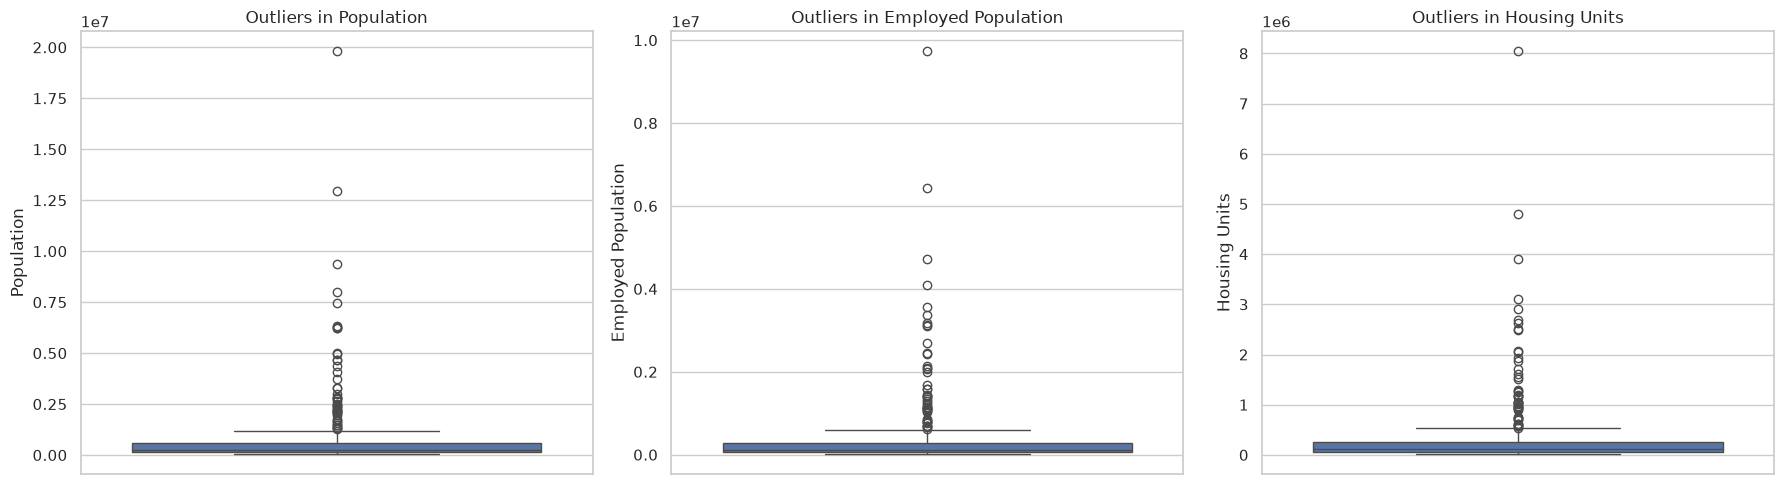

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, main_variables):
    sns.boxplot(
        data=df_2024_metro,
        y=column,
        ax=ax
    )

    ax.set_title(f"Outliers in {column.replace('_', ' ').title()}")
    ax.set_ylabel(column.replace("_", " ").title())

plt.tight_layout()
plt.show()

- ## Log-scale distributions — Compare metro sizes more clearly
Our dataset has a large difference between the smallest and largest metro areas. That can make the normal histograms and boxplots difficult to interpret.

A logarithmic scale helps us see the smaller and medium-sized metros more clearly.

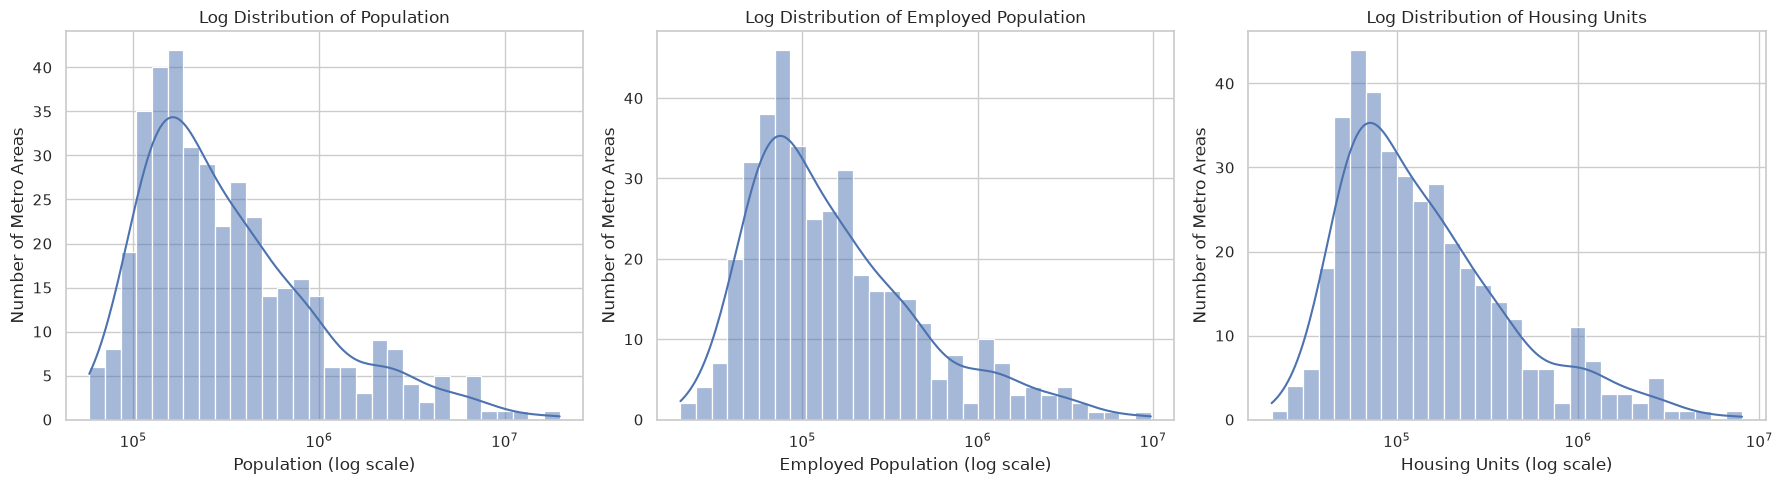

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, main_variables):
    sns.histplot(
        data=df_2024_metro,
        x=column,
        bins=30,
        kde=True,
        log_scale=True,
        ax=ax
    )

    ax.set_title(f"Log Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel(f"{column.replace('_', ' ').title()} (log scale)")
    ax.set_ylabel("Number of Metro Areas")

plt.tight_layout()
plt.show()

- ## Correlation heatmap — Understand relationships between variables
We want to investigate whether population, employment and housing move together across metropolitan areas.

How to interpret it:
- +1: Strong positive linear relationship.
- 0: Little or no linear relationship.
- -1: Strong negative linear relationship.

**Important:** This correlation is across different metro areas at one point in time. It does not prove that increasing housing causes population growth, or that these variables can predict future growth. We'll need historical periods for that.

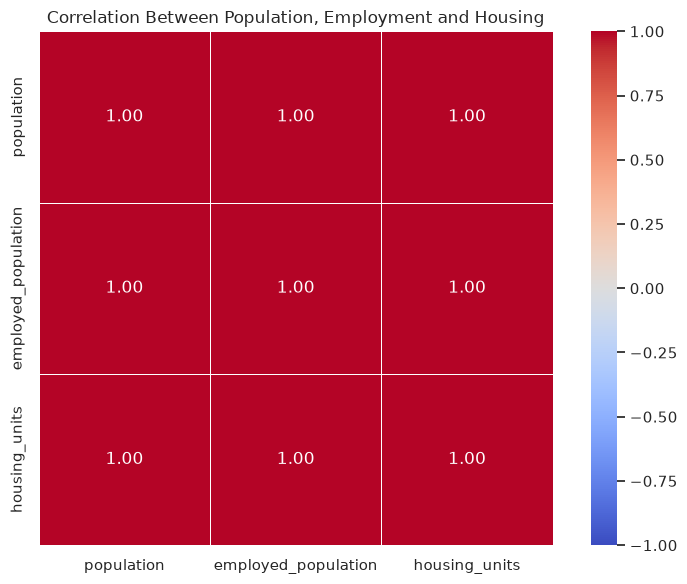

In [9]:
correlation_data = df_2024_metro[main_variables]

correlation_matrix = correlation_data.corr(method="pearson")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Population, Employment and Housing")
plt.tight_layout()
plt.show()

- ## Consistency checks — Find suspicious measurements

We can calculate:
- Employed population as a proportion of total population.
- Number of residents per housing unit.
- Housing units per 1,000 residents.
These are useful diagnostic indicators, not necessarily direct model inputs.

In [10]:
df_2024_metro["employed_to_total_population"] = (
    df_2024_metro["employed_population"]
    / df_2024_metro["population"]
)

df_2024_metro["people_per_housing_unit"] = (
    df_2024_metro["population"]
    / df_2024_metro["housing_units"]
)

df_2024_metro["housing_per_1000_people"] = (
    df_2024_metro["housing_units"]
    / df_2024_metro["population"]
    * 1000
)

display(
    df_2024_metro[
        [
            "metro_name",
            "employed_to_total_population",
            "people_per_housing_unit",
            "housing_per_1000_people"
        ]
    ].describe().round(3)
)

,employed_to_total_population,people_per_housing_unit,housing_per_1000_people
count,393.0,393.0,393.0
mean,0.466,2.295,440.832
std,0.047,0.251,48.376
min,0.229,1.394,299.652
25%,0.44,2.188,419.637
50%,0.47,2.279,438.732
75%,0.497,2.383,456.937
max,0.58,3.337,717.471


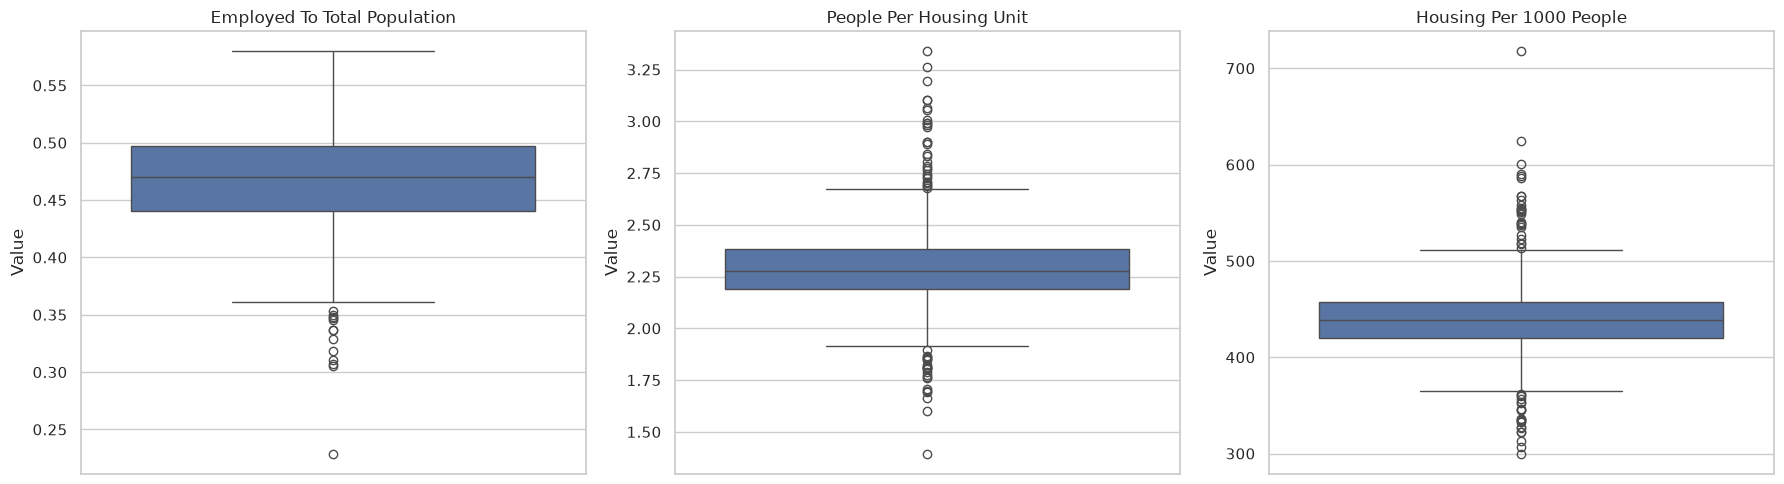

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ratio_columns = [
    "employed_to_total_population",
    "people_per_housing_unit",
    "housing_per_1000_people"
]

for ax, column in zip(axes, ratio_columns):
    sns.boxplot(
        data=df_2024_metro,
        y=column,
        ax=ax
    )

    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

## Observations
1. Employment-to-Population Ratio: The average employment-to-total-population ratio is approximately 46.6%, with a median of 47%. This indicates that employment represents a relatively consistent proportion of the total population across most metropolitan areas. However, the minimum value of 22.9% suggests some considerable variation between cities.

2. People per Housing Unit: On average, approximately 2.3 people live in each housing unit. The relatively low standard deviation (0.251) indicates that household occupancy is fairly consistent across the metropolitan areas.

3. Housing Availability: There are approximately 441 housing units per 1,000 people on average. The median of 439 is close to the mean, suggesting a relatively balanced distribution across the dataset. However, the maximum value of 717 indicates that some metropolitan areas have substantially more housing units relative to their population.

4. Overall Consistency: The mean and median values of all three indicators are relatively close, suggesting that their distributions are not heavily skewed overall. Nevertheless, the minimum and maximum values highlight differences in employment and housing characteristics across metropolitan areas.
Overall conclusion
The dataset demonstrates relatively consistent employment and housing patterns across most metropolitan areas, while also capturing meaningful variations between individual cities. These differences are important for our Terra Shift project because they may help identify relationships between population growth, employment patterns, and housing availability when developing predictive models.

## Three-variable bubble chart — Show all three together
- X-axis: Population
- Y-axis: Employed population
- Bubble size: Housing units

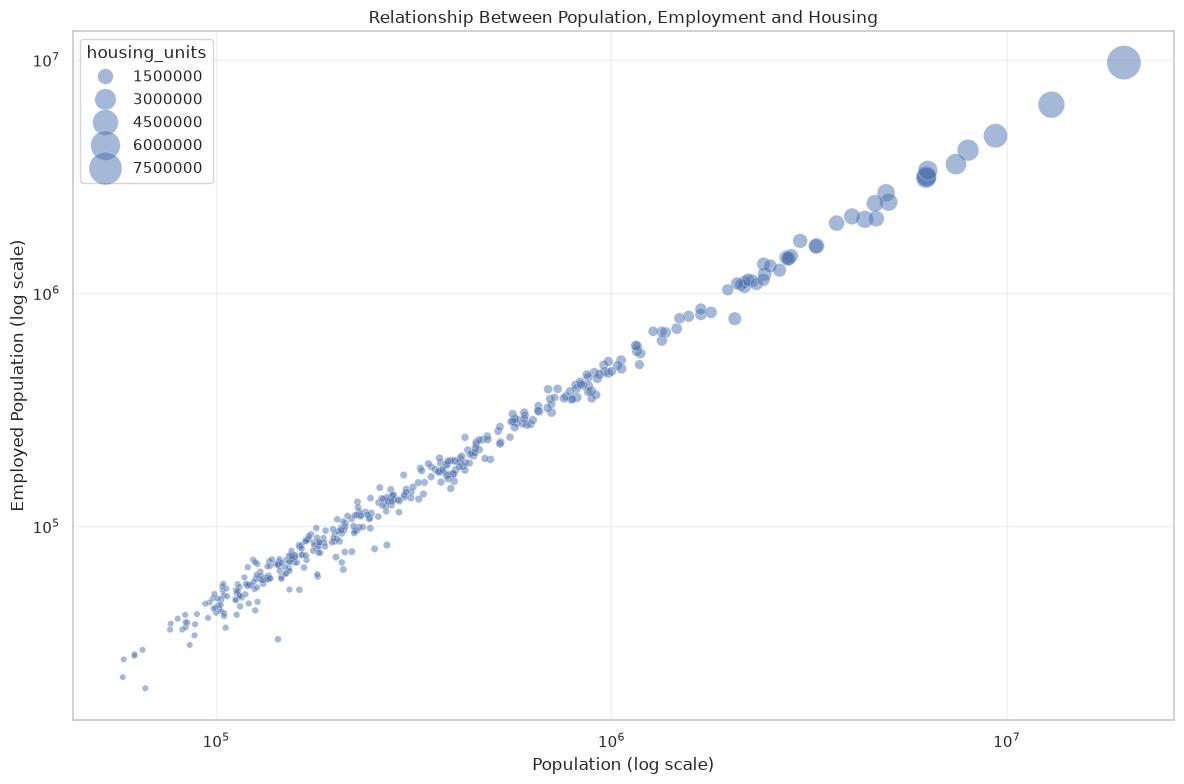

In [12]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df_2024_metro,
    x=df_2024_metro["population"].astype(float),
    y=df_2024_metro["employed_population"].astype(float),
    size=df_2024_metro["housing_units"].astype(float),
    sizes=(20, 600),
    alpha=0.5,
    legend="brief"
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Relationship Between Population, Employment and Housing"
)

plt.xlabel("Population (log scale)")
plt.ylabel("Employed Population (log scale)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- ### Outlier Detection and Treatment Strategy

The dataset contains metropolitan areas of considerably different sizes, resulting in naturally occurring extreme values in population, employment and housing measurements.

We will use the Interquartile Range (IQR) method to identify potential outliers. However, observations will not be removed solely because they fall outside the statistical boundaries.

Each flagged observation will be investigated using its original Census records, geographical identifiers and corresponding historical data.

Valid extreme observations will be retained to preserve the actual differences between metropolitan areas. Logarithmic transformation and robust scaling will also be evaluated during model preparation to reduce the influence of differences in measurement scales.

Observations will only be corrected or excluded when a genuine data-quality issue is identified and cannot be reliably resolved.

This approach helps preserve useful geographical variation while maintaining the reliability of the dataset.

## 5. Outlier Detection and Analysis

We use the Interquartile Range (IQR) method to identify potential
outliers in population, employed population and housing units.

Observations outside the IQR boundaries are flagged for further
investigation. They are not automatically removed from the dataset.

This gives us the number and percentage of potential outliers for each variable.

In [13]:
# Variables to investigate
outlier_columns = [
    "population",
    "employed_population",
    "housing_units"
]

# Store outlier summaries and individual records
outlier_summary = []
outlier_records = []

for column in outlier_columns:

    # Calculate quartiles and IQR
    Q1 = df_2024_metro[column].quantile(0.25)
    Q3 = df_2024_metro[column].quantile(0.75)

    IQR = Q3 - Q1

    # Calculate IQR boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify potential outliers
    mask = (
        (df_2024_metro[column] < lower_bound) |
        (df_2024_metro[column] > upper_bound)
    )

    outliers = df_2024_metro.loc[mask]

    # Store summary
    outlier_summary.append({
        "Variable": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (len(outliers) / len(df_2024_metro)) * 100
    })

    # Store individual outlier records
    for _, row in outliers.iterrows():
        outlier_records.append({
            "metro_id": row["metro_id"],
            "metro_name": row["metro_name"],
            "variable": column,
            "value": row[column],
            "lower_bound": lower_bound,
            "upper_bound": upper_bound
        })


# Create summary DataFrame
outlier_summary = pd.DataFrame(outlier_summary)

print("IQR Outlier Detection Summary")
display(outlier_summary.round(2))

IQR Outlier Detection Summary


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,population,146386.0,577726.0,431340.0,-500624.0,1224736.0,47,11.96
1,employed_population,67610.0,281608.0,213998.0,-253387.0,602605.0,47,11.96
2,housing_units,65459.0,253987.0,188528.0,-217333.0,536779.0,47,11.96


### Identify the metropolitan areas

In [14]:
# Convert detected outliers into a DataFrame
outlier_details = pd.DataFrame(outlier_records)

print("Total potential outlier observations:", len(outlier_details))

display(
    outlier_details.sort_values(
        by=["variable", "value"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

Total potential outlier observations: 141


,metro_id,metro_name,variable,value,lower_bound,upper_bound
0,35620,"New York-Newark-Jersey City, NY-NJ",employed_population,9727497,-253387.0,602605.0
1,31080,"Los Angeles-Long Beach-Anaheim, CA",employed_population,6423173,-253387.0,602605.0
2,16980,"Chicago-Naperville-Elgin, IL-IN",employed_population,4724716,-253387.0,602605.0
3,19100,"Dallas-Fort Worth-Arlington, TX",employed_population,4098208,-253387.0,602605.0
4,26420,"Houston-Pasadena-The Woodlands, TX",employed_population,3570995,-253387.0,602605.0
...,...,...,...,...,...,...
136,36420,"Oklahoma City, OK",population,1463267,-500624.0,1224736.0
137,31140,"Louisville/Jefferson County, KY-IN",population,1372558,-500624.0,1224736.0
138,32820,"Memphis, TN-MS-AR",population,1341924,-500624.0,1224736.0
139,40060,"Richmond, VA",population,1341248,-500624.0,1224736.0


### Find metros flagged in multiple variables
This is particularly interesting for our project.

For example, if a metropolitan area is flagged in population, employment and housing, it may simply be a very large metro.

If it is flagged only in housing, we may want to investigate its housing characteristics more closely.

In [15]:
# Count how many variables flagged each metro
outlier_frequency = (
    outlier_details
    .groupby(["metro_id", "metro_name"])
    .agg(
        flagged_variables=("variable", "count"),
        variables=("variable", lambda x: ", ".join(sorted(x)))
    )
    .reset_index()
    .sort_values(
        by="flagged_variables",
        ascending=False
    )
)

print("Metropolitan Areas Flagged Across Multiple Variables")

display(outlier_frequency)

Metropolitan Areas Flagged Across Multiple Variables


,metro_id,metro_name,flagged_variables,variables
0,12060,"Atlanta-Sandy Springs-Roswell, GA",3,"employed_population, housing_units, population"
1,12420,"Austin-Round Rock-San Marcos, TX",3,"employed_population, housing_units, population"
2,12580,"Baltimore-Columbia-Towson, MD",3,"employed_population, housing_units, population"
3,14460,"Boston-Cambridge-Newton, MA-NH",3,"employed_population, housing_units, population"
5,16740,"Charlotte-Concord-Gastonia, NC-SC",3,"employed_population, housing_units, population"
6,16980,"Chicago-Naperville-Elgin, IL-IN",3,"employed_population, housing_units, population"
7,17140,"Cincinnati, OH-KY-IN",3,"employed_population, housing_units, population"
8,17410,"Cleveland, OH",3,"employed_population, housing_units, population"
12,19820,"Detroit-Warren-Dearborn, MI",3,"employed_population, housing_units, population"
9,18140,"Columbus, OH",3,"employed_population, housing_units, population"


### Investigation and Treatment of Inconsistent Observations

After applying the IQR method, we examined metropolitan areas flagged in one or more variables to understand whether their unusual values represented general differences in metropolitan size or isolated irregularities.

Most flagged metropolitan areas, including Atlanta, Chicago, Dallas, Los Angeles and New York, were identified across all three variables: population, employed population and housing units. This indicates that their unusually high measurements are consistent with their overall metropolitan scale.

We also identified two cases requiring closer attention:

- **Buffalo-Cheektowaga, NY:** Flagged only in housing units. Since the unusual value was isolated to one variable, this metropolitan area was selected for exclusion from the initial modelling dataset.
- **Salt Lake City-Murray, UT:** Flagged in population and employed population. Its values will be retained for further investigation because the anomaly occurs across two related variables.

The remaining metropolitan areas were retained. In particular, major metropolitan areas flagged across all three variables were not removed because their measurements represent genuine differences in urban population and scale.

**Decision:** Buffalo-Cheektowaga, NY will be excluded from the initial modelling dataset, while Salt Lake City-Murray, UT and the other flagged metropolitan areas will be retained. The original dataset will be preserved so that this decision can be reviewed when historical data becomes available.

In [16]:
# Preserve the complete dataset before applying exclusions
df_2024_original = df_2024_metro.copy()

# Identify metros flagged in exactly one variable
single_variable_outliers = outlier_frequency[
    outlier_frequency["flagged_variables"] == 1
]

# Display the metropolitan areas selected for exclusion
print("Metropolitan areas flagged in only one variable:")

display(
    single_variable_outliers[
        ["metro_id", "metro_name", "variables"]
    ]
)

# Create a separate modelling dataset
excluded_metro_ids = single_variable_outliers["metro_id"]

df_2024_analysis = df_2024_original[
    ~df_2024_original["metro_id"].isin(excluded_metro_ids)
].copy()

# Display results
print("Original records:", len(df_2024_original))
print("Excluded records:", len(excluded_metro_ids))
print("Remaining records:", len(df_2024_analysis))

Metropolitan areas flagged in only one variable:


,metro_id,metro_name,variables
4,15380,"Buffalo-Cheektowaga, NY",housing_units


Original records: 393
Excluded records: 1
Remaining records: 392


In [17]:
print("Excluded metropolitan areas:")

display(
    df_2024_original[
        df_2024_original["metro_id"].isin(excluded_metro_ids)
    ][["metro_id", "metro_name"]]
)

print("\nRemaining dataset shape:")
print(df_2024_analysis.shape)

print("\nRemaining duplicate metro IDs:")
print(df_2024_analysis["metro_id"].duplicated().sum())

Excluded metropolitan areas:


,metro_id,metro_name
52,15380,"Buffalo-Cheektowaga, NY"



Remaining dataset shape:
(392, 13)

Remaining duplicate metro IDs:
0


## Putting data into there respective folders

In [19]:
import requests
import pandas as pd
from pathlib import Path

# --------------------------------
# 1. Census API request
# --------------------------------

BASE_URL = "https://api.census.gov/data/2024/acs/acs5"

variables = [
    "NAME",
    "B01003_001E",  # Total population
    "B01003_001M",  # Population margin of error
    "B23025_004E",  # Civilian employed population (16+)
    "B23025_004M",  # Employment margin of error
    "B25001_001E",  # Total housing units
    "B25001_001M"   # Housing units margin of error
]

params = {
    "get": ",".join(variables),
    "for": "metropolitan statistical area/micropolitan statistical area:*",
    "key": CENSUS_API_KEY
}

response = requests.get(BASE_URL, params=params, timeout=60)

print("HTTP Status:", response.status_code)

response.raise_for_status()

data = response.json()

df_2024 = pd.DataFrame(data[1:], columns=data[0])

print("Total records received:", len(df_2024))
display(df_2024.head())


# --------------------------------
# 2. Define existing project folders
# --------------------------------

PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FINAL_DIR = PROJECT_DIR / "data" / "final"


# --------------------------------
# 3. Save original API response
# --------------------------------

df_2024.to_csv(
    RAW_DIR / "acs_2024_raw.csv",
    index=False
)


# --------------------------------
# 4. Save cleaned dataset
# --------------------------------

df_2024_metro.to_csv(
    PROCESSED_DIR / "acs_2024_metro_cleaned.csv",
    index=False
)


# --------------------------------
# 5. Save final analysis dataset
# --------------------------------

df_2024_analysis.to_csv(
    FINAL_DIR / "acs_2024_metro_final.csv",
    index=False
)


# --------------------------------
# 6. Confirm saved files
# --------------------------------

print("All datasets saved successfully!")

print("\nRaw data:")
print(RAW_DIR / "acs_2024_raw.csv")

print("\nProcessed data:")
print(PROCESSED_DIR / "acs_2024_metro_cleaned.csv")

print("\nFinal data:")
print(FINAL_DIR / "acs_2024_metro_final.csv")

HTTP Status: 200
Total records received: 935


,NAME,B01003_001E,B01003_001M,B23025_004E,B23025_004M,B25001_001E,B25001_001M,metropolitan statistical area/micropolitan statistical area
0,"Aberdeen, SD Micro Area",41925,-555555555,21733,621,19988,77,10100
1,"Aberdeen, WA Micro Area",77053,-555555555,29849,880,36967,70,10140
2,"Abilene, TX Metro Area",180408,-555555555,80232,1653,75799,288,10180
3,"Ada, OK Micro Area",38235,-555555555,17599,391,17531,64,10220
4,"Adrian, MI Micro Area",98415,-555555555,44757,822,43761,177,10300


All datasets saved successfully!

Raw data:
/home/zayed/terra-shift/data/raw/acs_2024_raw.csv

Processed data:
/home/zayed/terra-shift/data/processed/acs_2024_metro_cleaned.csv

Final data:
/home/zayed/terra-shift/data/final/acs_2024_metro_final.csv
